Prep work:

*   Download student csv predictions from I-Learn
*   Rename files to team8-module3-predictions.csv where team8 is the name of the team
*   Make sure file is one column and remove any extra columns
*   Make sure the heading is set to "price" (without quotes)
*   Upload student csv predictions to session storage area.
*   Upload module3-holdout-answers.csv found in the Canvas module (DO NOT SHARE THIS FILE)
*   Run the notebook






In [71]:
# MODULE 03 - HOUSING HOLDOUT GRADING

from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_error, median_absolute_error

# THESE DETERMINE THE AUTO GRADER PARAMETER AND RANGES FOR 100 AND 0
grading_criteria = 'R2'
level_for_top_score = .89
level_for_bottom_score = .81

# READ IN THE CSV FILES
team_dir = Path("./")
teams = team_dir.glob("*-predictions.csv")
team_list = []
for team in teams:
  # print(latent_file)
  team_list.append((str(team).split("-",1)[0],team))

# print(team_list)

In [72]:
# READ IN THE HOLDOUT ANSWERS
targets_file = "module3-holdout-answers.csv"
targets = pd.read_csv(targets_file)
# targets

In [73]:
# ARE THE STUDENT DATASETS THE CORRECT LENGTH
student_datasets = {}
for (group, file) in team_list:
  ds = pd.read_csv(file)

  if ds.shape != targets.shape:
    if ds.shape[1] == 2 and ds.shape[0] == targets.shape[0]:
      ds = ds.drop(ds.columns[[0]],axis = 1)
      student_datasets[group] = ds
      print(f"Group {group} added successfully after removing extra index column")
    else:
      print(f"Error group {group} ds had {ds.shape} rows and columns instead of the expected {targets.shape}. It will be excluded.")
  else:
    student_datasets[group] = ds
    print(f"Group {group} added successfully")

Group team1 added successfully
Group team3 added successfully
Group team5 added successfully
Group team4 added successfully
Group team2 added successfully


In [74]:
# student_datasets

In [75]:
def recommended_grade(amount):
  '''
  A simple min max scaler to identify a recommended score for the holdout set
  '''
  min_allowed = level_for_bottom_score
  max_allowed = level_for_top_score
  if amount>max_allowed:
    return 100
  elif amount<min_allowed:
    return 0
  else:
    return (amount - min_allowed) / (max_allowed - min_allowed)*100


In [76]:
results_dict = {}

In [77]:
for group, student_ds in student_datasets.items():
  student_dict = {}
  # print(group,cm)
  student_ds.columns=['price']
  mse = root_mean_squared_error(targets, student_ds)
  # print("{} - RMSE: {}".format(group, mse))

  student_dict["RMSE"] = root_mean_squared_error(targets, student_ds)
  student_dict["Mean Abs Error"] = mean_absolute_error(targets, student_ds)
  student_dict["Median Abs Error"] = median_absolute_error(targets, student_ds)
  student_dict["R2"] = r2_score(targets, student_ds)

  combined = pd.concat([targets, student_ds], axis=1)
  combined.columns = ["target", "pred"]
  combined["absdiff"] = (combined["target"] - combined["pred"]).abs()
  combined["absdiff_pct"] = combined["absdiff"] / combined["target"]

  shower = pd.DataFrame(student_ds, columns = ['price'])
  shower.columns = ['predictions']
  testfinal = pd.concat([shower,targets['price']],axis=1)
  testfinal['difference'] = testfinal['price']-testfinal['predictions']
  testfinal['percent_difference'] = abs(testfinal['difference']/testfinal['price'])
  testfinal['percent_bucket'] = [ "above 20%" if i >= 0.2 else "below 20%" for i in testfinal.percent_difference ]

  # testfinal

  student_dict['dataset'] = testfinal
  percents = [5, 10, 20]
  for percent in percents:
    student_dict[f"Percent of houses within {percent} percent"] = len(combined[combined["absdiff_pct"] <= (percent /100)]) / len(combined) * 100
  student_dict["Grade"] = recommended_grade(student_dict[grading_criteria])

  results_dict[group] = student_dict

In [78]:
# df['predictions']

In [79]:
# results_dict

In [80]:
results_df = pd.DataFrame(results_dict)
results_ds_trans = results_df.transpose()
results_ds_trans = results_ds_trans.drop(columns=["Grade"])
results_ds_trans = results_ds_trans.drop(columns=["dataset"])

results_ds_trans = results_ds_trans.round(2)
results_ds_trans = results_ds_trans.sort_values(by="R2",ascending=False)


In [81]:
# results_df

-------------------------------- TEAM1 RESULTS ---------------------------------

 Within 5%: 32.79603223806571%
 Within 10%: 57.284562926224424%
 Within 20%: 82.82703037817731%
 R^2: 0.8818628760466515%
 RMSE: 129073.24142466241
 Mean Absolute Error: 66699.94854308742
 Median Aboslute Error: 37171.0


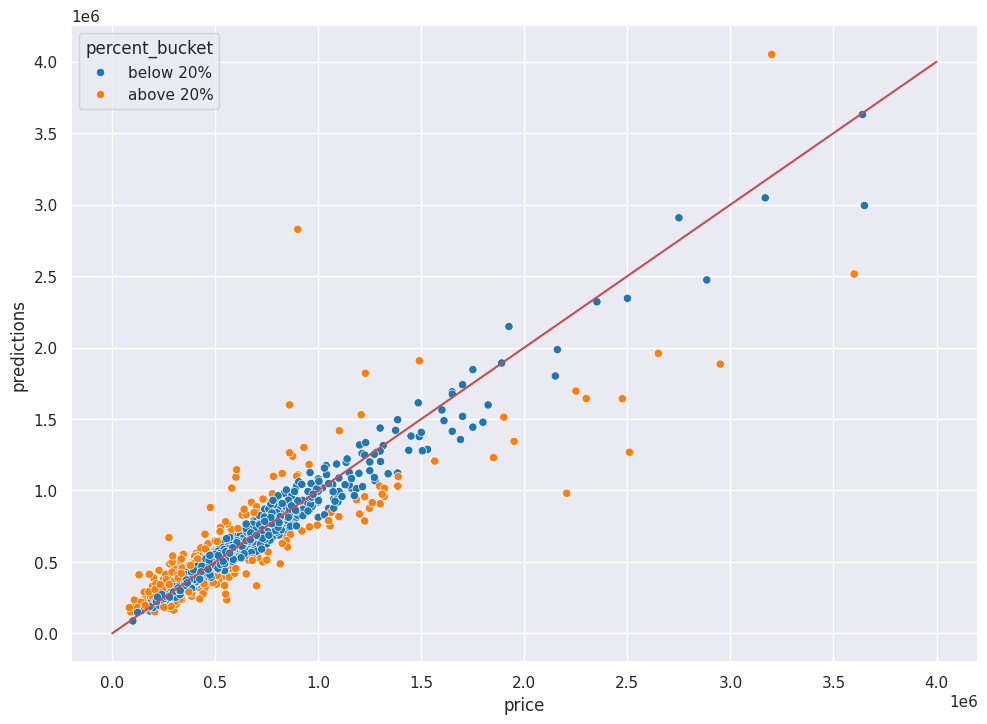

-----------------------------------------------------------------------------




-------------------------------- TEAM3 RESULTS ---------------------------------

 Within 5%: 31.43211407315561%
 Within 10%: 55.67265964042157%
 Within 20%: 83.32300061996281%
 R^2: 0.8953737135206051%
 RMSE: 121468.43199482997
 Mean Absolute Error: 66436.23432114074
 Median Aboslute Error: 38628.31


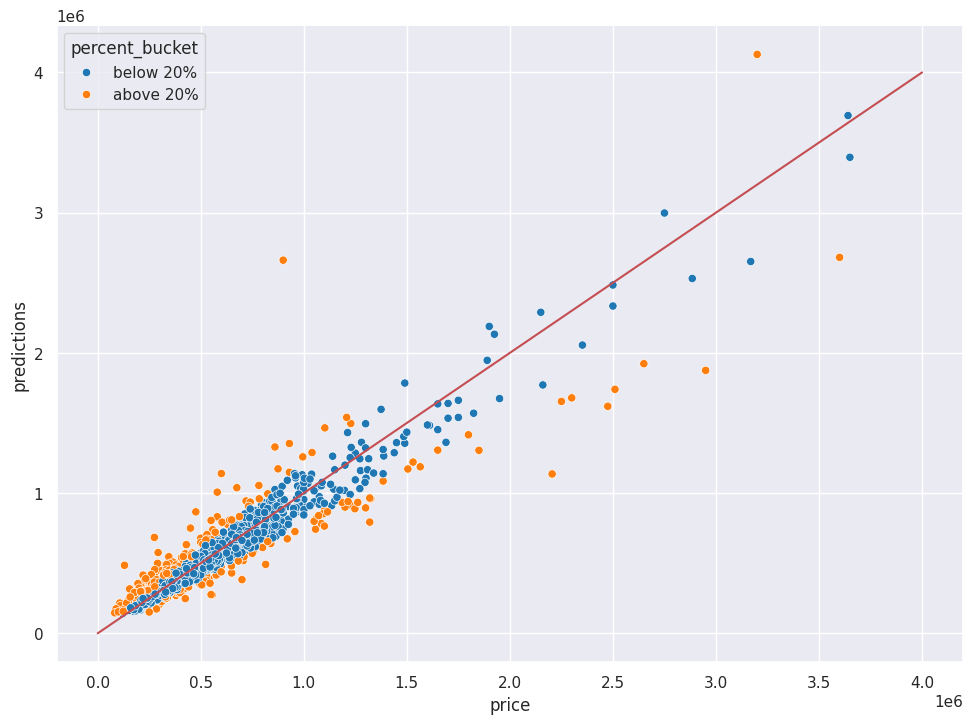

-----------------------------------------------------------------------------




-------------------------------- TEAM5 RESULTS ---------------------------------

 Within 5%: 31.928084314941103%
 Within 10%: 55.05269683818971%
 Within 20%: 81.40111593304403%
 R^2: 0.8502262016082154%
 RMSE: 145331.8967993067
 Mean Absolute Error: 69589.89998202109
 Median Aboslute Error: 38489.659999999974


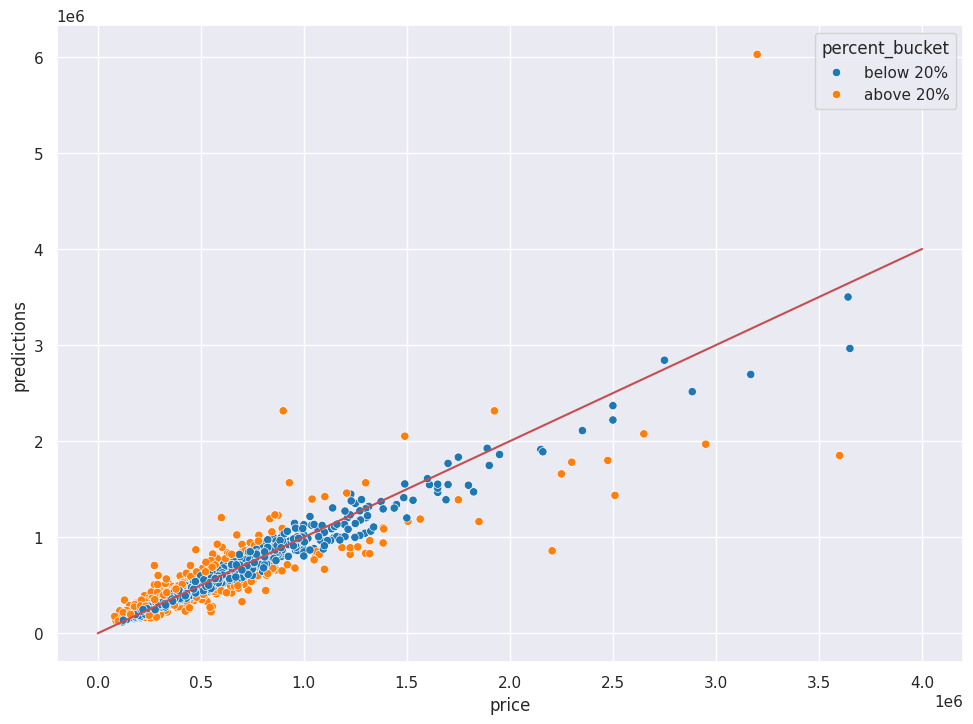

-----------------------------------------------------------------------------




-------------------------------- TEAM4 RESULTS ---------------------------------

 Within 5%: 34.22194668319901%
 Within 10%: 57.284562926224424%
 Within 20%: 83.63298202107873%
 R^2: 0.9023549658194909%
 RMSE: 117345.94876386761
 Mean Absolute Error: 63950.18877247366
 Median Aboslute Error: 37953.439999999944


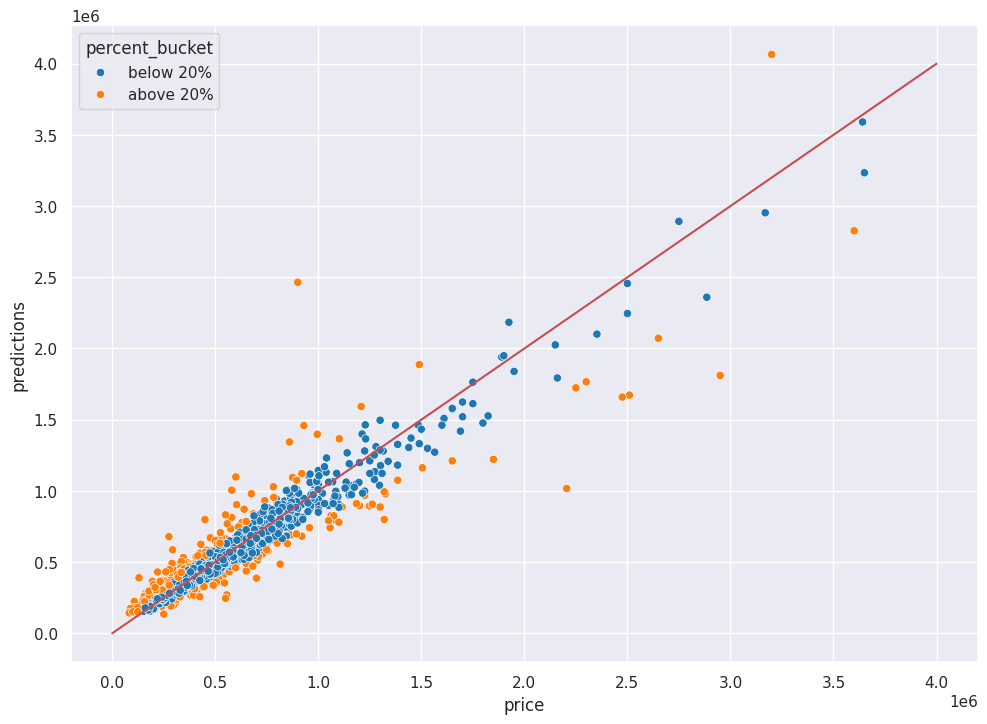

-----------------------------------------------------------------------------




-------------------------------- TEAM2 RESULTS ---------------------------------

 Within 5%: 22.070675759454435%
 Within 10%: 41.97148171109733%
 Within 20%: 70.73775573465592%
 R^2: 0.7588561795397124%
 RMSE: 184408.56501763346
 Mean Absolute Error: 94646.98156230626
 Median Aboslute Error: 56195.619999999995


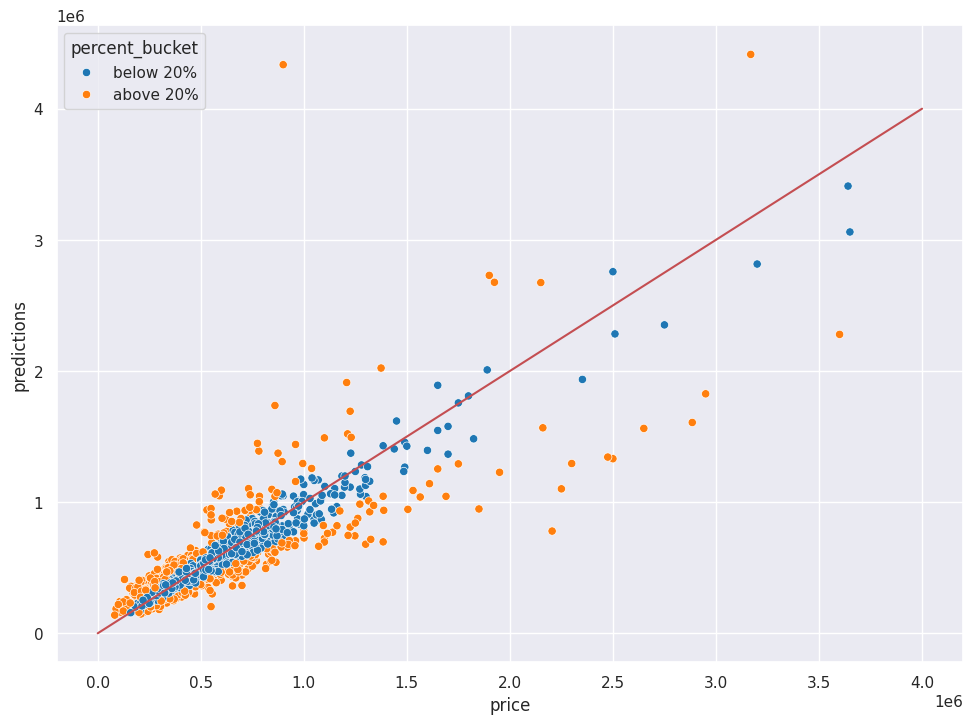

-----------------------------------------------------------------------------






In [82]:
sns.set(rc={'figure.figsize':(11.7,8.27)})
for team_results in results_dict.items():
  testfinal = team_results[1]['dataset']
  # print(team_results['dataset'])
  # print(f"R-Squared Value: {r2}")
  print(f"-------------------------------- {team_results[0].upper()} RESULTS ---------------------------------\n")
  print(f" Within 5%: {team_results[1]['Percent of houses within 5 percent']}%\n",
  f"Within 10%: {team_results[1]['Percent of houses within 10 percent']}%\n",
  f"Within 20%: {team_results[1]['Percent of houses within 20 percent']}%\n",
  f"R^2: {team_results[1]['R2']}%\n",
  f"RMSE: {team_results[1]['RMSE']}\n",
  f"Mean Absolute Error: {team_results[1]['Mean Abs Error']}\n",
  f"Median Aboslute Error: {team_results[1]['Median Abs Error']}")


  color_dict = dict({'below 20%':'tab:blue',
                    'above 20%': 'tab:orange'})
  # print(testfinal['abspercentmiss'].describe(percentiles=[.1,.2,.3,.4,.5,.6,.7,.8,.9,.95]))
  xlims=(0,4e6)
  ylims=(0,4e6)
  ax = sns.scatterplot(data=testfinal,x='price',y='predictions',hue="percent_bucket",palette=color_dict)
  # ax.set(xscale="log", yscale="log", xlim=xlims, ylim=ylims)
  ax.plot(xlims,xlims, color='r')
  # plt.legend(labels=['perfect',"below 5",'above 5','10-20%','above 20'])
  plt.show()
  print(f"-"*77)
  print("\n"*3)


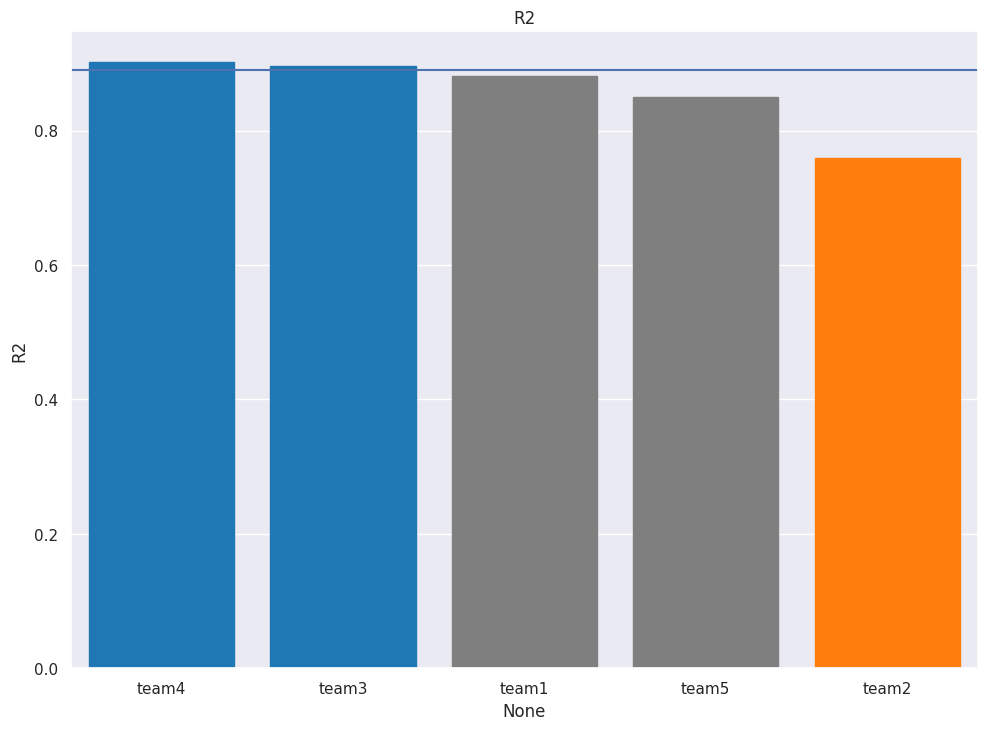

,RMSE,Mean Abs Error,Median Abs Error,R2,Percent of houses within 5 percent,Percent of houses within 10 percent,Percent of houses within 20 percent
team4,117345.948764,63950.188772,37953.44,0.902355,34.221947,57.284563,83.632982
team3,121468.431995,66436.234321,38628.31,0.895374,31.432114,55.67266,83.323001
team1,129073.241425,66699.948543,37171.0,0.881863,32.796032,57.284563,82.82703
team5,145331.896799,69589.899982,38489.66,0.850226,31.928084,55.052697,81.401116
team2,184408.565018,94646.981562,56195.62,0.758856,22.070676,41.971482,70.737756


In [83]:
# GENERATE GRAPHICS FOR TEAMS
# THESE CAN BE SHARED WITH THE STUDENTS

graph = sns.barplot(data=results_ds_trans,y=grading_criteria,x=results_ds_trans.index)
graph.set_title(grading_criteria)
graph.axhline(level_for_top_score)
for bar in graph.patches:
    if bar.get_height() >= level_for_top_score:
        bar.set_color('tab:blue')
    elif bar.get_height() <0:
      bar.set_color('tab:red')
    elif bar.get_height() < level_for_bottom_score:
      bar.set_color('tab:orange')
    else:
        bar.set_color('tab:grey')
#The plot is shown
plt.show()
results_ds_trans

In [84]:
results_ds_trans = results_df.transpose()

results_ds_trans = results_ds_trans.drop(columns=["dataset"])
results_ds_trans = results_ds_trans.sort_values(by=grading_criteria,ascending=False)
results_ds_trans.to_csv("class_results.csv")
results_ds_trans

,RMSE,Mean Abs Error,Median Abs Error,R2,Percent of houses within 5 percent,Percent of houses within 10 percent,Percent of houses within 20 percent,Grade
team4,117345.948764,63950.188772,37953.44,0.902355,34.221947,57.284563,83.632982,100
team3,121468.431995,66436.234321,38628.31,0.895374,31.432114,55.67266,83.323001,100
team1,129073.241425,66699.948543,37171.0,0.881863,32.796032,57.284563,82.82703,89.828595
team5,145331.896799,69589.899982,38489.66,0.850226,31.928084,55.052697,81.401116,50.282752
team2,184408.565018,94646.981562,56195.62,0.758856,22.070676,41.971482,70.737756,0
